# 15_final_model.ipynb — โมเดลหลักสำหรับเปเปอร์และ dashboard

## เป้าหมาย: ผลดีที่สุด โดยเลือกโมเดลอย่างยุติธรรม

Notebook 11–14 ใช้ test set เทียบกันมาหลายรอบแล้ว ถ้าเลือกโมเดลสุดท้ายจาก test จะเป็น *data snooping* (ผล test จะดูดีเกินจริง) จึงแบ่ง validation ออกเป็น 2 ส่วนตามผู้ป่วย:

| ส่วน | ใช้ทำอะไร |
|---|---|
| train (64%) | เทรนโมเดล |
| **val_es** (8%) | early stopping เท่านั้น |
| **val_sel** (8%) | เลือกโมเดล/น้ำหนัก ensemble, calibration, ตัด risk tier |
| test (20%) | วัดผล **ครั้งเดียว** ตอนจบ |

## Candidate
- **B. XGBoost + history** — จาก notebook 14
- **D. LSTM K=5** — จาก notebook 14 (5 seed เฉลี่ยกัน)
- **Blend** — w·LSTM + (1−w)·XGBoost โดยเลือก w บน val_sel

โมเดลที่ให้ ROC-AUC บน val_sel สูงสุดจะเป็นโมเดลหลัก แม้จะชนะแค่เล็กน้อย

## Output
calibrated probability, risk tier 3 ระดับแบบ percentile (แทน cost-optimal threshold ที่ใช้กับ base rate 47% ไม่ได้), fairness และไฟล์โมเดลสำหรับ dashboard

ต้องการ: `readmission_features.py` **เวอร์ชันล่าสุด** (มีฟังก์ชัน history/LSTM เพิ่ม), torch, xgboost, `split_assignment.csv`, `11_{label}/test_predictions.csv`

## 0. Config + Imports

In [1]:
LABEL_MODE = "any"
RANDOM_STATE = 42
RAW_PATH = "../data/diabetic_data.csv"
SPLIT_PATH = "../outputs/split_assignment.csv"
STACKING_11 = f"../outputs/11_{LABEL_MODE}/test_predictions.csv"   # โมเดลหลักเดิม ไว้เทียบ
OUT_DIR = f"../outputs/15_final_{LABEL_MODE}"
MODEL_DIR = f"../models/final_{LABEL_MODE}"

K_SEQ, N_SEEDS = 5, 5
HIDDEN, DROPOUT, BATCH, LR, MAX_EPOCHS, PATIENCE = 64, 0.3, 512, 1e-3, 40, 5
TIERS = {"High": 0.20, "Medium": 0.30}   # top 20% = High, ถัดไป 30% = Medium, ที่เหลือ = Low
N_BOOT_TEST = 500

In [ ]:
import os, json, copy, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import xgboost as xgb
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.model_selection import GroupShuffleSplit
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score)
from readmission_features import (load_prepared, attach_split, build_history_features,
                                  build_nn_inputs, build_seq_index)

BLEND_GRID = np.round(np.arange(0, 1.01, 0.1), 1)
torch.set_num_threads(max(1, os.cpu_count() - 1))
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)

## 1. ข้อมูล + แบ่ง validation เป็น val_es / val_sel ตามผู้ป่วย

In [3]:
X, y, groups, meta, R = load_prepared(RAW_PATH, LABEL_MODE)
split = attach_split(meta, SPLIT_PATH).astype(object)

val_idx = np.where(split == "val")[0]
gss = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=RANDOM_STATE)
es_rel, sel_rel = next(gss.split(val_idx, groups=groups[val_idx]))
split[val_idx[es_rel]], split[val_idx[sel_rel]] = "val_es", "val_sel"

rows = {s: np.where(split == s)[0] for s in ["train", "val_es", "val_sel", "test"]}
y_np = y.values.astype(np.float32)
for s, r in rows.items():
    print(f"{s:8s} n={len(r):6,}  patients={len(np.unique(groups[r])):6,}  base rate={y_np[r].mean():.4f}")
assert len(set(groups[rows["val_es"]]) & set(groups[rows["val_sel"]])) == 0

Hist = build_history_features(meta)
X_B = pd.concat([X, Hist], axis=1)          # feature ของ XGBoost + history
visit_number = R["visit_number"].values
first_visit_all = visit_number == 1

train    n=63,605  patients=44,791  base rate=0.4725
val_es   n= 7,954  patients= 5,599  base rate=0.4687
val_sel  n= 8,008  patients= 5,599  base rate=0.4793
test     n=19,773  patients=13,998  base rate=0.4651


## 2. เทรน B. XGBoost + history (early stopping บน val_es)

In [4]:
XGB_PARAMS = {"objective": "binary:logistic", "eval_metric": "logloss", "tree_method": "hist",
              "learning_rate": 0.03, "max_depth": 4, "subsample": 0.9, "min_child_weight": 5,
              "seed": RANDOM_STATE}

def dm(r, label=True):
    return xgb.DMatrix(X_B.iloc[r], label=y_np[r] if label else None)

bst = xgb.train(XGB_PARAMS, dm(rows["train"]), num_boost_round=3000,
                evals=[(dm(rows["val_es"]), "val_es")], early_stopping_rounds=100, verbose_eval=False)
it = (0, bst.best_iteration + 1)
pred = {"B": {s: bst.predict(dm(rows[s], False), iteration_range=it) for s in ["val_sel", "test"]}}
print(f"XGBoost: {bst.best_iteration + 1} trees | val_sel ROC-AUC = {roc_auc_score(y_np[rows['val_sel']], pred['B']['val_sel']):.4f}")

# baseline A (ไม่มี history) ไว้ใช้เทียบในตารางสุดท้าย
def dmA(r, label=True):
    return xgb.DMatrix(X.iloc[r], label=y_np[r] if label else None)
bstA = xgb.train(XGB_PARAMS, dmA(rows["train"]), num_boost_round=3000,
                 evals=[(dmA(rows["val_es"]), "val_es")], early_stopping_rounds=100, verbose_eval=False)
pred["A"] = {s: bstA.predict(dmA(rows[s], False), iteration_range=(0, bstA.best_iteration + 1))
             for s in ["val_sel", "test"]}

XGBoost: 1127 trees | val_sel ROC-AUC = 0.6885


## 3. เทรน D. LSTM K=5 (5 seed, early stopping บน val_es)

In [5]:
F, nn_artifacts = build_nn_inputs(R, Hist, rows["train"])
D_IN = F.shape[1]
idx_seq, L_seq = build_seq_index(visit_number, meta["patient_nbr"].values, K_SEQ)
F_pad = torch.from_numpy(np.vstack([F, np.zeros((1, D_IN), np.float32)]))
y_t = torch.from_numpy(y_np)

class SeqNet(nn.Module):
    def __init__(self, d_in, h=HIDDEN, drop=DROPOUT):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(drop))
        self.lstm = nn.LSTM(h, h, batch_first=True)
        self.head = nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Dropout(drop), nn.Linear(h, 1))
    def forward(self, x, lengths):
        packed = pack_padded_sequence(self.inp(x), lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        return self.head(h_n[-1]).squeeze(-1)

def batch(r):
    return F_pad[torch.from_numpy(idx_seq[r])], torch.from_numpy(L_seq[r])

@torch.no_grad()
def predict_nn(model, r):
    model.eval()
    return torch.cat([torch.sigmoid(model(*batch(r[b:b + 4096]))) for b in range(0, len(r), 4096)]).numpy()

def train_nn(seed):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = SeqNet(D_IN)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
    lossf = nn.BCEWithLogitsLoss()
    best, best_state, bad, n_ep = -1.0, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        perm = rng.permutation(rows["train"])
        for b in range(0, len(perm), BATCH):
            r = perm[b:b + BATCH]
            opt.zero_grad()
            loss = lossf(model(*batch(r)), y_t[torch.from_numpy(r)])
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        auc = roc_auc_score(y_np[rows["val_es"]], predict_nn(model, rows["val_es"]))
        n_ep = epoch
        if auc > best + 1e-4:
            best, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best, n_ep

lstm_models, pv, pt = [], [], []
for s in range(N_SEEDS):
    t0 = time.time()
    model, best, n_ep = train_nn(RANDOM_STATE + s)
    lstm_models.append(model)
    pv.append(predict_nn(model, rows["val_sel"])); pt.append(predict_nn(model, rows["test"]))
    print(f"LSTM seed {s}: epochs={n_ep}, val_es ROC-AUC={best:.4f}, "
          f"val_sel ROC-AUC={roc_auc_score(y_np[rows['val_sel']], pv[-1]):.4f} ({time.time() - t0:.0f}s)")
pred["D"] = {"val_sel": np.mean(pv, axis=0), "test": np.mean(pt, axis=0)}
print(f"LSTM ensemble ({N_SEEDS} seeds) val_sel ROC-AUC = {roc_auc_score(y_np[rows['val_sel']], pred['D']['val_sel']):.4f}")

LSTM seed 0: epochs=17, val_es ROC-AUC=0.7022, val_sel ROC-AUC=0.6918 (30s)
LSTM seed 1: epochs=17, val_es ROC-AUC=0.7020, val_sel ROC-AUC=0.6911 (28s)
LSTM seed 2: epochs=18, val_es ROC-AUC=0.7021, val_sel ROC-AUC=0.6905 (30s)
LSTM seed 3: epochs=18, val_es ROC-AUC=0.7026, val_sel ROC-AUC=0.6909 (30s)
LSTM seed 4: epochs=18, val_es ROC-AUC=0.7028, val_sel ROC-AUC=0.6927 (31s)
LSTM ensemble (5 seeds) val_sel ROC-AUC = 0.6937


## 4. เลือกโมเดลบน val_sel

Blend = w·LSTM + (1−w)·XGBoost (w = 0 คือ XGBoost ล้วน, w = 1 คือ LSTM ล้วน) ใช้ grid หยาบ 0.1 เพื่อลดการ overfit กับ val_sel

 w_lstm  ROC_AUC  PR_AUC
    0.0   0.6885  0.6695
    0.1   0.6903  0.6720
    0.2   0.6918  0.6741
    0.3   0.6930  0.6757
    0.4   0.6940  0.6770
    0.5   0.6946  0.6780
    0.6   0.6950  0.6786
    0.7   0.6951  0.6787
    0.8   0.6949  0.6784
    0.9   0.6944  0.6777
    1.0   0.6937  0.6768

>>> โมเดลหลัก: Blend (w_lstm=0.7)  (val_sel ROC-AUC = 0.6951)


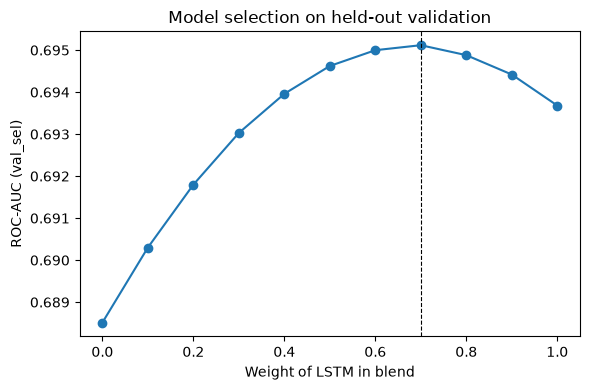

In [6]:
yv = y_np[rows["val_sel"]]
blend_scores = pd.DataFrame([{
    "w_lstm": w,
    "ROC_AUC": roc_auc_score(yv, w * pred["D"]["val_sel"] + (1 - w) * pred["B"]["val_sel"]),
    "PR_AUC": average_precision_score(yv, w * pred["D"]["val_sel"] + (1 - w) * pred["B"]["val_sel"]),
} for w in BLEND_GRID])
best_w = float(blend_scores.loc[blend_scores["ROC_AUC"].idxmax(), "w_lstm"])
print(blend_scores.round(4).to_string(index=False))

final_name = {0.0: "B. XGBoost + history", 1.0: "D. LSTM K=5"}.get(best_w, f"Blend (w_lstm={best_w})")
print(f"\n>>> โมเดลหลัก: {final_name}  (val_sel ROC-AUC = {blend_scores['ROC_AUC'].max():.4f})")

def final_raw(s):
    return best_w * pred["D"][s] + (1 - best_w) * pred["B"][s]
pred["Final"] = {s: final_raw(s) for s in ["val_sel", "test"]}

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(blend_scores["w_lstm"], blend_scores["ROC_AUC"], "o-")
ax.axvline(best_w, ls="--", c="k", lw=0.8)
ax.set_xlabel("Weight of LSTM in blend"); ax.set_ylabel("ROC-AUC (val_sel)")
ax.set_title("Model selection on held-out validation")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/1_blend_selection.png", dpi=150); plt.show()

## 5. Calibration + Risk tiers (fit บน val_sel)

- **Isotonic calibration** → ความน่าจะเป็นที่ตรงกับความจริง ใช้แสดงใน dashboard
- **Risk tier แบบ percentile**: ตัดที่ score ของ val_sel — High = top 20%, Medium = 30% ถัดไป, Low = ที่เหลือ
  เหตุผล: base rate 47% ทำให้ threshold แบบ cost-optimal แจ้งเตือนเกือบทุกคน (ดู notebook 11) การตัดตาม percentile คุมภาระงานของทีมได้แน่นอน และคงเกณฑ์ alarm fatigue (High ≤ 20%) ไว้

In [7]:
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(pred["Final"]["val_sel"], yv)
p_te = iso.predict(pred["Final"]["test"])

s_val = pred["Final"]["val_sel"]
cut_high = float(np.quantile(s_val, 1 - TIERS["High"]))
cut_med = float(np.quantile(s_val, 1 - TIERS["High"] - TIERS["Medium"]))

def tier_of(score):
    return np.where(score >= cut_high, "High", np.where(score >= cut_med, "Medium", "Low"))

print(f"Tier cut-offs (raw score): High ≥ {cut_high:.4f}, Medium ≥ {cut_med:.4f}")
print(f"เทียบเป็น calibrated probability: High ≥ {iso.predict([cut_high])[0]:.3f}, Medium ≥ {iso.predict([cut_med])[0]:.3f}")

Tier cut-offs (raw score): High ≥ 0.6190, Medium ≥ 0.4573
เทียบเป็น calibrated probability: High ≥ 0.617, Medium ≥ 0.473


## 6. วัดผลบน Test (ครั้งเดียว)

เทียบกับ:
- **Stacking เดิม** (notebook 11) — โมเดลหลักตัวก่อน
- **A. XGBoost tuned** — baseline ที่ไม่มี history

In [8]:
te = rows["test"]; y_te = y_np[te]; g_te = groups[te]; fv = first_visit_all[te]
test_meta = meta.iloc[te][["encounter_id"]].reset_index(drop=True)
stk = test_meta.merge(pd.read_csv(STACKING_11)[["encounter_id", "proba_calibrated"]], on="encounter_id", how="left")
assert stk["proba_calibrated"].notna().all()

models = {
    "Stacking (notebook 11)": stk["proba_calibrated"].values,
    "A. XGBoost tuned": pred["A"]["test"],
    "B. XGBoost + history": pred["B"]["test"],
    "D. LSTM K=5": pred["D"]["test"],
    f"FINAL: {final_name}": pred["Final"]["test"],   # ใช้ score ก่อน calibrate วัด ROC/PR (isotonic สร้างค่าซ้ำ ทำให้ PR-AUC ต่ำลงเล็กน้อย)
}
base = y_te.mean()

def summarize(p, ii=None):
    ii = np.arange(len(y_te)) if ii is None else ii
    yt, pp = y_te[ii], p[ii]
    top = np.argsort(-pp)[: int(0.2 * len(pp))]
    return {"ROC_AUC": roc_auc_score(yt, pp), "PR_AUC": average_precision_score(yt, pp),
            "Precision@top20%": yt[top].mean()}

tab = pd.DataFrame({k: {**summarize(v),
                        "ROC_AUC first visit": roc_auc_score(y_te[fv], v[fv]),
                        "ROC_AUC has history": roc_auc_score(y_te[~fv], v[~fv])}
                    for k, v in models.items()}).T
tab["Lift@top20%"] = tab["Precision@top20%"] / base
print(f"Test n={len(te):,}, base rate={base:.4f}\n")
print(tab.round(4).to_string())

bs = brier_score_loss(y_te, p_te)
print(f"\nFINAL calibrated — Brier={bs:.4f}, Brier skill score={1 - bs / brier_score_loss(y_te, np.full(len(y_te), yv.mean())):.4f}")

Test n=19,773, base rate=0.4651

                           ROC_AUC  PR_AUC  Precision@top20%  ROC_AUC first visit  ROC_AUC has history  Lift@top20%
Stacking (notebook 11)      0.6806  0.6365            0.6980               0.6447               0.6467       1.5007
A. XGBoost tuned            0.6946  0.6595            0.7190               0.6618               0.6663       1.5458
B. XGBoost + history        0.6969  0.6669            0.7236               0.6621               0.6792       1.5556
D. LSTM K=5                 0.7014  0.6705            0.7246               0.6666               0.6857       1.5578
FINAL: Blend (w_lstm=0.7)   0.7031  0.6732            0.7329               0.6684               0.6892       1.5758

FINAL calibrated — Brier=0.2179, Brier skill score=0.1247


In [9]:
# Paired cluster bootstrap: FINAL เทียบกับโมเดลอื่น
fin = f"FINAL: {final_name}"
rng = np.random.default_rng(RANDOM_STATE)
uniq = np.unique(g_te)
by_pt = pd.Series(np.arange(len(g_te))).groupby(g_te).apply(np.array)
refs = [k for k in models if k != fin]
dd = {k: {"ROC_AUC": [], "PR_AUC": []} for k in refs}
own = {"ROC_AUC": [], "PR_AUC": []}
for b in range(N_BOOT_TEST):
    ii = np.concatenate(by_pt.loc[rng.choice(uniq, len(uniq), replace=True)].values)
    f_roc, f_pr = roc_auc_score(y_te[ii], models[fin][ii]), average_precision_score(y_te[ii], models[fin][ii])
    own["ROC_AUC"].append(f_roc); own["PR_AUC"].append(f_pr)
    for k in refs:
        dd[k]["ROC_AUC"].append(f_roc - roc_auc_score(y_te[ii], models[k][ii]))
        dd[k]["PR_AUC"].append(f_pr - average_precision_score(y_te[ii], models[k][ii]))

ci = lambda a: np.percentile(a, [2.5, 97.5])
print(f"{fin}: ROC-AUC {tab.loc[fin, 'ROC_AUC']:.4f} ({ci(own['ROC_AUC'])[0]:.4f}–{ci(own['ROC_AUC'])[1]:.4f}), "
      f"PR-AUC {tab.loc[fin, 'PR_AUC']:.4f} ({ci(own['PR_AUC'])[0]:.4f}–{ci(own['PR_AUC'])[1]:.4f})\n")
delta_rows = []
for k in refs:
    r = {"vs": k}
    for met in ["ROC_AUC", "PR_AUC"]:
        lo, hi = ci(dd[k][met])
        r[f"Δ {met}"] = f"{tab.loc[fin, met] - tab.loc[k, met]:+.4f} ({lo:+.4f}, {hi:+.4f})" + (" *" if lo > 0 or hi < 0 else "")
    delta_rows.append(r)
delta_tab = pd.DataFrame(delta_rows)
print("ผลต่างของโมเดลหลัก + 95% CI (* = มีนัยสำคัญ)")
print(delta_tab.to_string(index=False))

FINAL: Blend (w_lstm=0.7): ROC-AUC 0.7031 (0.6941–0.7111), PR-AUC 0.6732 (0.6586–0.6857)

ผลต่างของโมเดลหลัก + 95% CI (* = มีนัยสำคัญ)
                    vs                    Δ ROC_AUC                     Δ PR_AUC
Stacking (notebook 11) +0.0226 (+0.0193, +0.0260) * +0.0367 (+0.0321, +0.0409) *
      A. XGBoost tuned +0.0085 (+0.0064, +0.0107) * +0.0137 (+0.0107, +0.0172) *
  B. XGBoost + history +0.0062 (+0.0041, +0.0084) * +0.0063 (+0.0036, +0.0093) *
           D. LSTM K=5 +0.0017 (+0.0008, +0.0025) * +0.0028 (+0.0014, +0.0039) *


## 7. Risk tiers บน Test + Calibration

            n  observed_rate  mean_predicted  readmissions  % of patients  % of all readmissions captured  lift vs base
tier                                                                                                                   
High     3852          0.734           0.741        2826.0         19.481                       30.726999         1.577
Medium   5905          0.533           0.540        3150.0         29.864                       34.250000         1.147
Low     10016          0.322           0.342        3221.0         50.655                       35.021999         0.691

แจ้งเตือนเฉพาะ High:        precision=0.734, recall=0.307
แจ้งเตือน High + Medium:   precision=0.612, recall=0.650


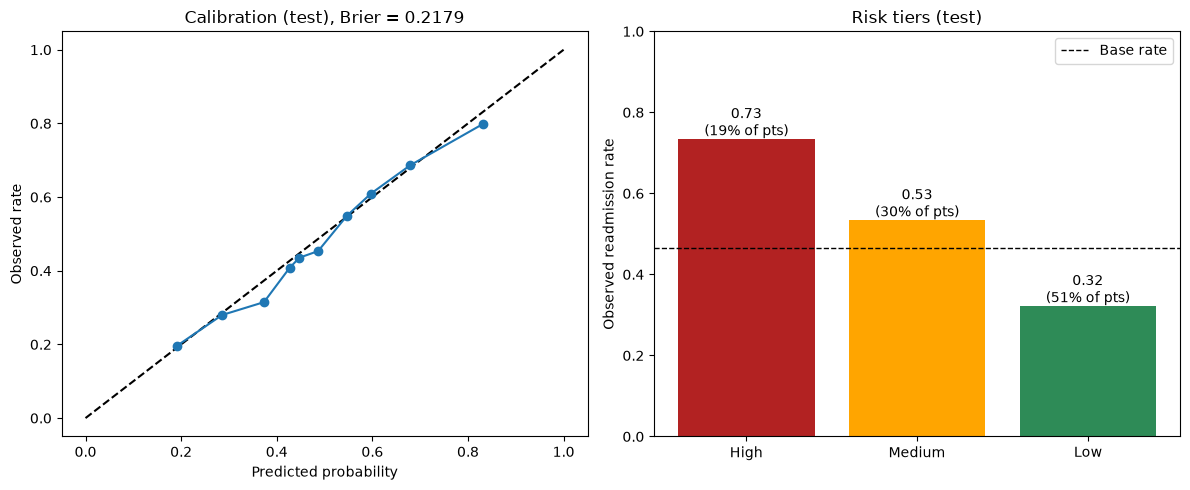

In [10]:
tier_te = tier_of(pred["Final"]["test"])
tiers = (pd.DataFrame({"tier": tier_te, "y": y_te, "p": p_te})
         .groupby("tier").agg(n=("y", "size"), observed_rate=("y", "mean"), mean_predicted=("p", "mean"),
                              readmissions=("y", "sum"))
         .reindex(["High", "Medium", "Low"]))
tiers["% of patients"] = tiers["n"] / tiers["n"].sum() * 100
tiers["% of all readmissions captured"] = tiers["readmissions"] / tiers["readmissions"].sum() * 100
tiers["lift vs base"] = tiers["observed_rate"] / base
print(tiers.round(3).to_string())

flag_high = tier_te == "High"
flag_hm = tier_te != "Low"
print(f"\nแจ้งเตือนเฉพาะ High:        precision={precision_score(y_te, flag_high):.3f}, recall={recall_score(y_te, flag_high):.3f}")
print(f"แจ้งเตือน High + Medium:   precision={precision_score(y_te, flag_hm):.3f}, recall={recall_score(y_te, flag_hm):.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
fp, mp = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
a1.plot([0, 1], [0, 1], "k--"); a1.plot(mp, fp, "o-")
a1.set_xlabel("Predicted probability"); a1.set_ylabel("Observed rate"); a1.set_title(f"Calibration (test), Brier = {bs:.4f}")
a2.bar(tiers.index, tiers["observed_rate"], color=["firebrick", "orange", "seagreen"])
a2.axhline(base, ls="--", c="k", lw=1, label="Base rate")
for i, (r, c) in enumerate(zip(tiers["observed_rate"], tiers["% of patients"])):
    a2.text(i, r + 0.01, f"{r:.2f}\n({c:.0f}% of pts)", ha="center")
a2.set_ylabel("Observed readmission rate"); a2.set_title("Risk tiers (test)"); a2.set_ylim(0, 1); a2.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/2_calibration_tiers.png", dpi=150); plt.show()

## 8. Fairness
ROC-AUC/PR-AUC (ไม่ขึ้นกับ threshold) + สัดส่วนที่ถูกจัดเป็น High และ recall ของ tier High ต่อกลุ่ม

In [11]:
demo = R.iloc[te][["age", "gender", "race"]].reset_index(drop=True)
p_raw_te = pred["Final"]["test"]
fair = {}
for col in ["age", "gender", "race"]:
    out = []
    for g in sorted(demo[col].unique()):
        mk = (demo[col] == g).values
        if mk.sum() < 30 or len(np.unique(y_te[mk])) < 2:
            continue
        out.append({"group": g, "n": int(mk.sum()), "base_rate": y_te[mk].mean(),
                    "ROC_AUC": roc_auc_score(y_te[mk], p_raw_te[mk]),
                    "PR_AUC": average_precision_score(y_te[mk], p_raw_te[mk]),
                    "% High": flag_high[mk].mean() * 100,
                    "recall(High)": recall_score(y_te[mk], flag_high[mk], zero_division=0)})
    fair[col] = pd.DataFrame(out).round(4)
    print(f"\n--- {col} ---\n{fair[col].to_string(index=False)}")
    fair[col].to_csv(f"{OUT_DIR}/fairness_{col}.csv", index=False)


--- age ---
   group    n  base_rate  ROC_AUC  PR_AUC  % High  recall(High)
 [10-20)  137     0.3723   0.7344  0.6397 11.6788        0.2353
 [20-30)  369     0.4878   0.8168  0.8047 30.3523        0.5167
 [30-40)  757     0.4267   0.8091  0.7694 22.4571        0.4365
 [40-50) 1909     0.4301   0.7081  0.6594 18.0199        0.3021
 [50-60) 3467     0.4364   0.7159  0.6799 19.0366        0.3344
 [60-70) 4356     0.4628   0.6992  0.6669 19.6740        0.3046
 [70-80) 4921     0.4840   0.6851  0.6665 20.0366        0.2989
 [80-90) 3284     0.5088   0.6623  0.6535 19.9452        0.2783
[90-100)  547     0.4278   0.6463  0.5683  9.5064        0.1496

--- gender ---
 group     n  base_rate  ROC_AUC  PR_AUC  % High  recall(High)
Female 10726     0.4726   0.7055  0.6764 20.8092        0.3214
  Male  9047     0.4563   0.6995  0.6690 17.9065        0.2900

--- race ---
          group     n  base_rate  ROC_AUC  PR_AUC  % High  recall(High)
AfricanAmerican  3697     0.4585   0.7048  0.6670 18.312

## 9. บันทึกโมเดลและผลทั้งหมด (สำหรับเปเปอร์และ dashboard)

In [12]:
bst.save_model(f"{MODEL_DIR}/xgb_history.json")
for i, m in enumerate(lstm_models):
    torch.save(m.state_dict(), f"{MODEL_DIR}/lstm_seed{i}.pt")
joblib.dump({
    "label_mode": LABEL_MODE, "final_name": final_name, "w_lstm": best_w,
    "xgb_best_iteration": int(bst.best_iteration + 1), "xgb_feature_names": list(X_B.columns),
    "lstm_config": {"K_SEQ": K_SEQ, "HIDDEN": HIDDEN, "DROPOUT": DROPOUT, "D_IN": D_IN, "N_SEEDS": N_SEEDS},
    "nn_artifacts": nn_artifacts, "isotonic": iso,
    "tier_cutoffs_raw": {"High": cut_high, "Medium": cut_med}, "tier_shares": TIERS,
}, f"{MODEL_DIR}/final_bundle.pkl")

tab.round(4).to_csv(f"{OUT_DIR}/test_metrics.csv")
delta_tab.to_csv(f"{OUT_DIR}/test_deltas.csv", index=False)
tiers.round(4).to_csv(f"{OUT_DIR}/risk_tiers.csv")
blend_scores.round(4).to_csv(f"{OUT_DIR}/blend_selection.csv", index=False)
pd.DataFrame({"encounter_id": test_meta["encounter_id"], "y_true": y_te, "proba_calibrated": p_te,
              "risk_tier": tier_te}).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)
print(f"บันทึกโมเดลไว้ที่ {MODEL_DIR}/ และผลไว้ที่ {OUT_DIR}/")

บันทึกโมเดลไว้ที่ ../models/final_any/ และผลไว้ที่ ../outputs/15_final_any/
